In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
%matplotlib inline

from matplotlib import*
import seaborn as sns

In [2]:
import tensorflow as tf
from tensorflow import keras

In [3]:
np.random.seed(19)
tf.random.set_seed(19)

In [4]:
import datetime

In [5]:
ask_df = pd.read_csv('XAGUSD_5 Mins_Ask_2023.01.01_2023.06.30-1.csv')   
bid_df = pd.read_csv('XAGUSD_5 Mins_Bid_2023.01.01_2023.06.30-1.csv')   

In [6]:
print(ask_df.head(3))
print(ask_df.tail(3))

            Time (UTC)    Open    High     Low   Close  Volume 
0  2023.01.02 23:00:00  24.102  24.125  24.083  24.125    0.351
1  2023.01.02 23:05:00  24.094  24.188  24.094  24.141    1.155
2  2023.01.02 23:10:00  24.143  24.148  24.022  24.027    0.882
                Time (UTC)    Open    High     Low   Close  Volume 
35217  2023.06.30 20:45:00  22.781  22.781  22.776  22.776   0.4212
35218  2023.06.30 20:50:00  22.776  22.797  22.774  22.786   0.6836
35219  2023.06.30 20:55:00  22.786  22.811  22.786  22.811   0.3712


In [7]:
print(bid_df.head(3))
print(bid_df.tail(3))

            Time (UTC)    Open    High     Low   Close  Volume 
0  2023.01.02 23:00:00  24.036  24.059  24.017  24.059   0.3480
1  2023.01.02 23:05:00  24.064  24.130  24.064  24.092   1.8458
2  2023.01.02 23:10:00  24.094  24.098  23.972  23.977   0.9030
                Time (UTC)    Open    High     Low   Close  Volume 
35217  2023.06.30 20:45:00  22.751  22.751  22.746  22.746    0.069
35218  2023.06.30 20:50:00  22.746  22.761  22.736  22.756    0.216
35219  2023.06.30 20:55:00  22.756  22.766  22.701  22.745    0.327


In [8]:
ask_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Time (UTC)  35220 non-null  str    
 1   Open        35220 non-null  float64
 2   High        35220 non-null  float64
 3   Low         35220 non-null  float64
 4   Close       35220 non-null  float64
 5   Volume      35220 non-null  float64
dtypes: float64(5), str(1)
memory usage: 2.3 MB


In [9]:
bid_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Time (UTC)  35220 non-null  str    
 1   Open        35220 non-null  float64
 2   High        35220 non-null  float64
 3   Low         35220 non-null  float64
 4   Close       35220 non-null  float64
 5   Volume      35220 non-null  float64
dtypes: float64(5), str(1)
memory usage: 2.3 MB


In [10]:
both = bid_df.merge(ask_df, left_on='Time (UTC)', right_on='Time (UTC)', how='outer')
both

,Time (UTC),Open_x,High_x,Low_x,Close_x,Volume _x,Open_y,High_y,Low_y,Close_y,Volume _y
0,2023.01.02 23:00:00,24.036,24.059,24.017,24.059,0.3480,24.102,24.125,24.083,24.125,0.3510
1,2023.01.02 23:05:00,24.064,24.130,24.064,24.092,1.8458,24.094,24.188,24.094,24.141,1.1550
2,2023.01.02 23:10:00,24.094,24.098,23.972,23.977,0.9030,24.143,24.148,24.022,24.027,0.8820
3,2023.01.02 23:15:00,23.977,23.980,23.938,23.980,0.8940,24.026,24.028,23.986,24.028,0.8940
4,2023.01.02 23:20:00,23.978,24.024,23.976,24.023,0.8880,24.026,24.073,24.023,24.073,0.9044
...,...,...,...,...,...,...,...,...,...,...,...
35215,2023.06.30 20:35:00,22.752,22.752,22.741,22.746,0.2752,22.782,22.782,22.771,22.776,1.8002
35216,2023.06.30 20:40:00,22.736,22.751,22.736,22.746,0.1410,22.775,22.781,22.775,22.776,0.7568
35217,2023.06.30 20:45:00,22.751,22.751,22.746,22.746,0.0690,22.781,22.781,22.776,22.776,0.4212
35218,2023.06.30 20:50:00,22.746,22.761,22.736,22.756,0.2160,22.776,22.797,22.774,22.786,0.6836


In [11]:
both.info()

<class 'pandas.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Time (UTC)  35220 non-null  str    
 1   Open_x      35220 non-null  float64
 2   High_x      35220 non-null  float64
 3   Low_x       35220 non-null  float64
 4   Close_x     35220 non-null  float64
 5   Volume _x   35220 non-null  float64
 6   Open_y      35220 non-null  float64
 7   High_y      35220 non-null  float64
 8   Low_y       35220 non-null  float64
 9   Close_y     35220 non-null  float64
 10  Volume _y   35220 non-null  float64
dtypes: float64(10), str(1)
memory usage: 3.6 MB


In [12]:
both.columns = ['stamp', 'bid_o', 'bid_h', 'bid_l', 'bid_c', 'bid_v',
                  'ask_o', 'ask_h', 'ask_l', 'ask_c', 'ask_v']

In [13]:
print(both.shape)
print(both.isna().sum().sum(), 'missing values')

(35220, 11)
0 missing values


In [14]:
file_obj2 = open('silver_merged.csv', 'w')
both.to_csv('silver_merged.csv', encoding='utf-8', index=False)
file_obj2.close()

In [15]:
df = pd.read_csv('silver_merged.csv', low_memory=False, sep=',')

In [16]:
df['vol_gap'] = df['ask_v'] - df['bid_v']
df['vol_gap_abs'] = (df['ask_v'] - df['bid_v']).abs()

In [17]:
df['gap_o'] = df['ask_o'] - df['bid_o']
df['gap_h'] = df['ask_h'] - df['bid_h']
df['gap_l'] = df['ask_l'] - df['bid_l']
df['gap_c'] = df['ask_c'] - df['bid_c']

In [18]:
data = df.drop(['ask_o', 'ask_h', 'ask_l', 'ask_c'], axis=1)

In [19]:
data['ts'] = pd.to_datetime(data['stamp'], utc=True)

In [20]:
data = data.drop(['stamp'], axis=1)

In [21]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype              
---  ------       --------------  -----              
 0   bid_o        35220 non-null  float64            
 1   bid_h        35220 non-null  float64            
 2   bid_l        35220 non-null  float64            
 3   bid_c        35220 non-null  float64            
 4   bid_v        35220 non-null  float64            
 5   ask_v        35220 non-null  float64            
 6   vol_gap      35220 non-null  float64            
 7   vol_gap_abs  35220 non-null  float64            
 8   gap_o        35220 non-null  float64            
 9   gap_h        35220 non-null  float64            
 10  gap_l        35220 non-null  float64            
 11  gap_c        35220 non-null  float64            
 12  ts           35220 non-null  datetime64[us, UTC]
dtypes: datetime64[us, UTC](1), float64(12)
memory usage: 3.5 MB


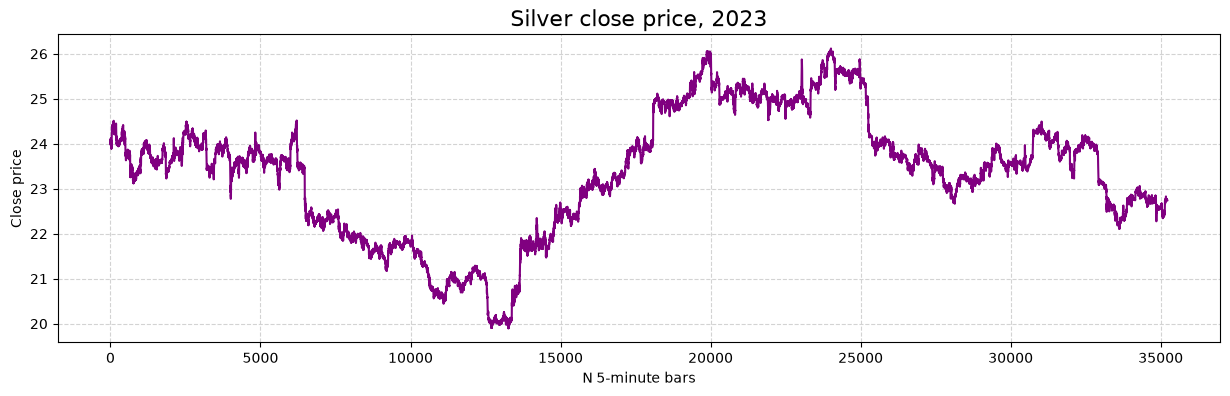

In [22]:
plt.figure(figsize=(15,4))
plt.plot(data['bid_c'], color='purple', linewidth=1.5)
plt.title('Silver close price, 2023', size=16)
plt.xlabel('N 5-minute bars')
plt.ylabel('Close price')
plt.grid(True, color='lightgray', linestyle='--')
plt.show()

In [23]:
data_chart = data.set_index('ts', inplace=False)

In [24]:
data_chart = data_chart.drop(['ask_v', 'vol_gap', 'vol_gap_abs',
                              'gap_o', 'gap_h', 'gap_l', 'gap_c'], axis=1)

findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


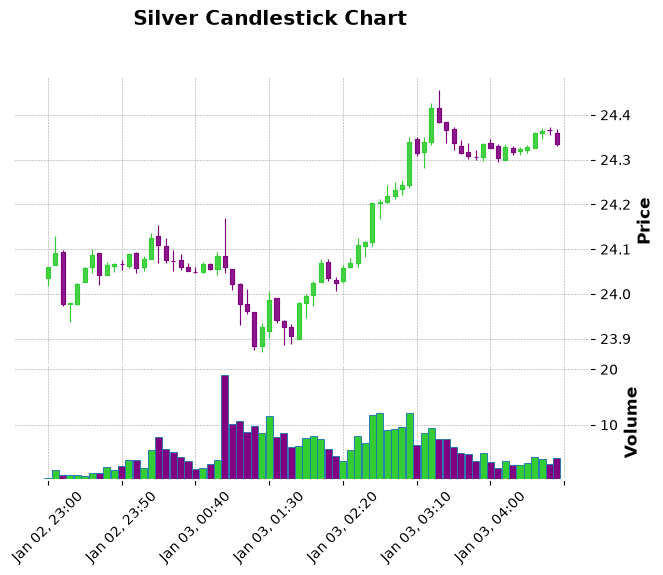

In [25]:
import mplfinance as mpf

data_chart.columns = ['Open', 'High', 'Low', 'Close', 'Volume']
mc = mpf.make_marketcolors(up='limegreen', down='purple', edge='inherit', wick='inherit', volume='inherit')
my_style = mpf.make_mpf_style(base_mpf_style='charles', marketcolors=mc)
mpf.plot(data_chart.iloc[0:70], type='candle', style=my_style, title='Silver Candlestick Chart', volume=True)

In [26]:
data_chart = []

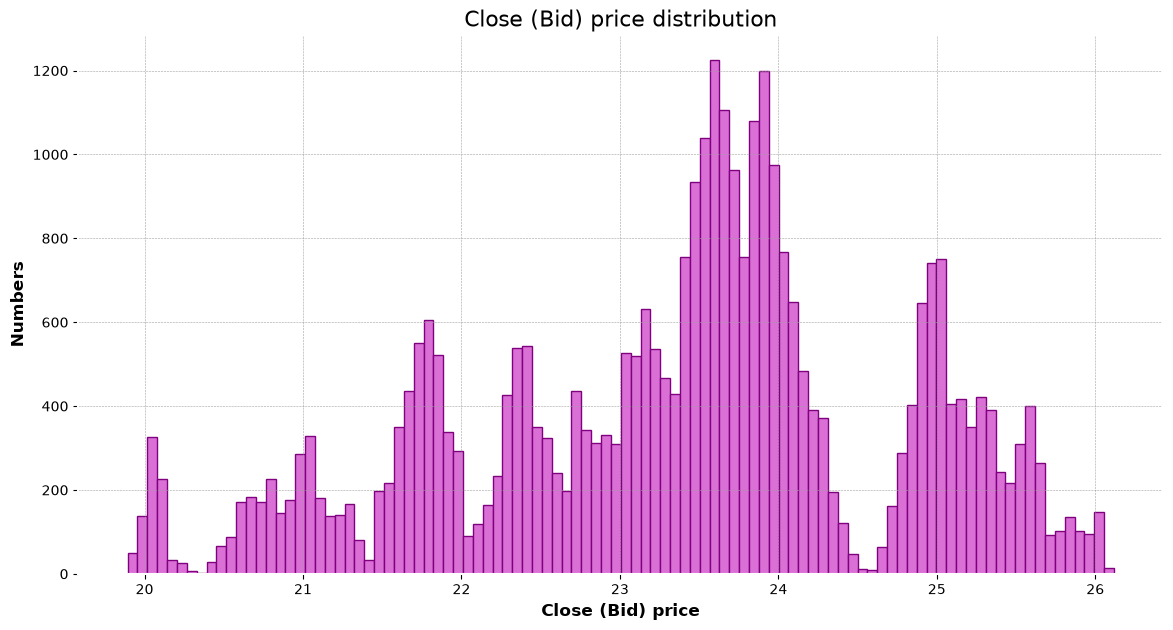

In [27]:
plt.figure(num=1, figsize=(14,7))
plt.hist(data['bid_c'], bins=100, color='orchid', edgecolor='purple')
plt.title('Close (Bid) price distribution', size=16)
plt.ylabel('Numbers', size=12)
plt.xlabel('Close (Bid) price', size=12)
plt.show()

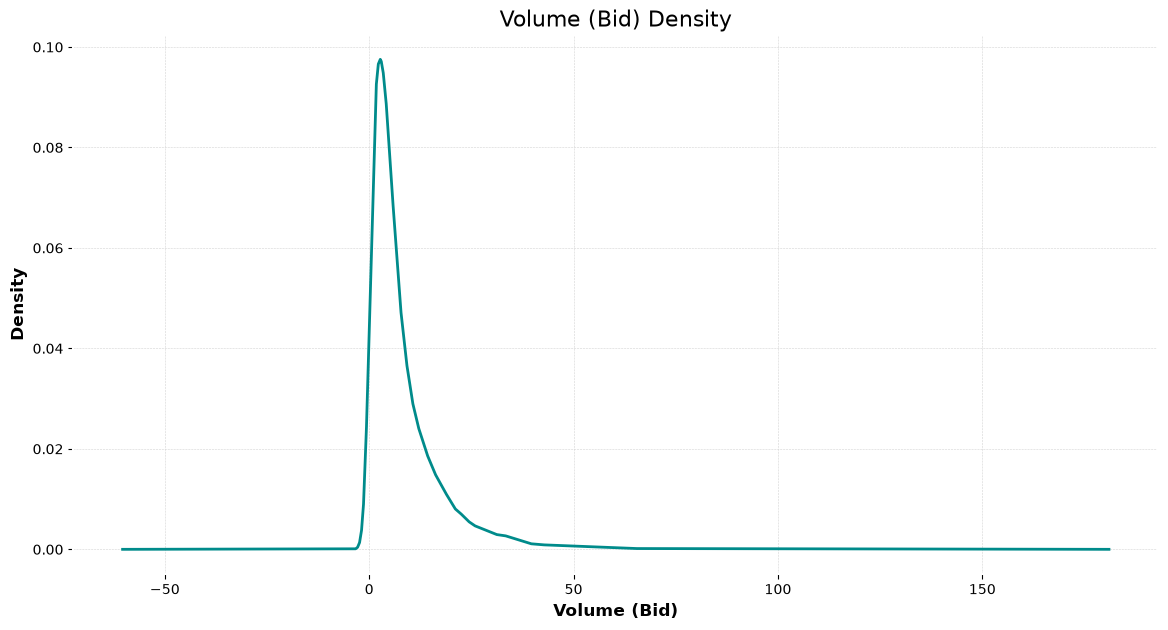

In [28]:
plt.figure(num=1, figsize=(14,7))
data['bid_v'].plot.kde(color='darkcyan', linewidth=2)
plt.title('Volume (Bid) Density', size=16)
plt.ylabel('Density', size=12)
plt.xlabel('Volume (Bid)', size=12)
plt.grid(True, color='lightgray', linestyle='--')
plt.show()

findfont: Failed to find font weight semibold, now using 700.


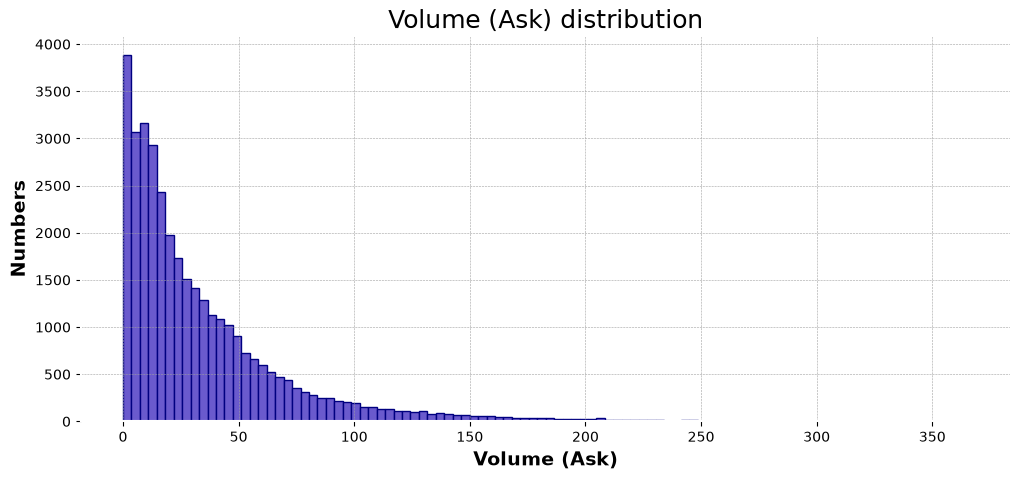

In [29]:
plt.figure(num=1, figsize=(12,5))
plt.hist(data['ask_v'], bins=100, color='slateblue', edgecolor='navy')
plt.title('Volume (Ask) distribution', size=18)
plt.ylabel('Numbers', size=14)
plt.xlabel('Volume (Ask)', size=14)
plt.show()

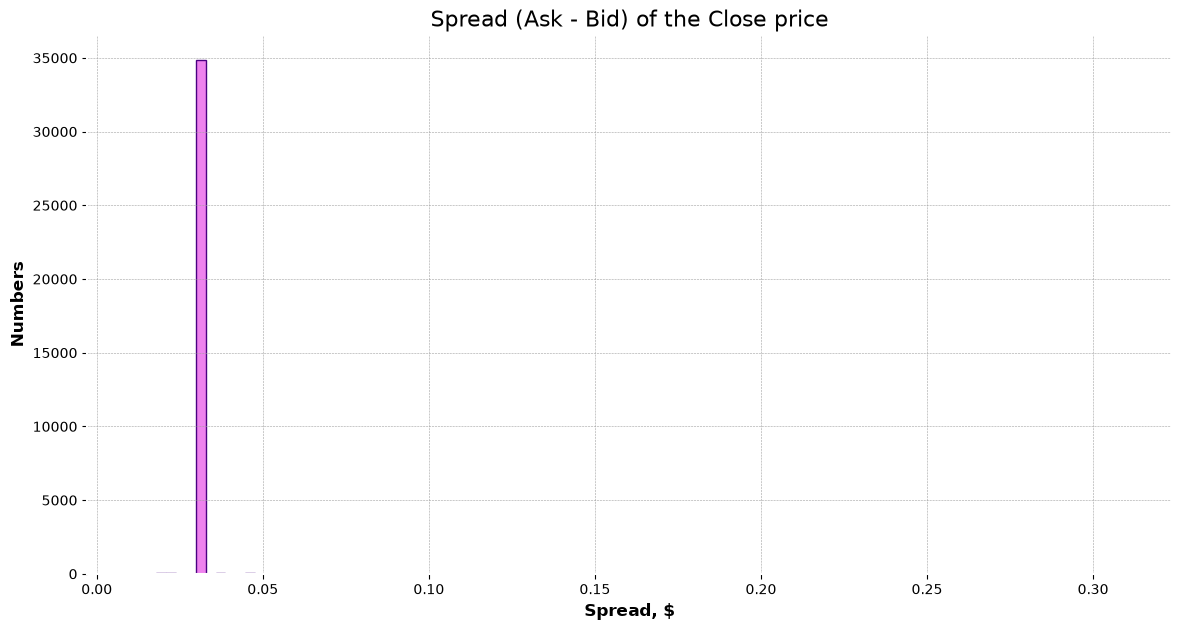

In [30]:
plt.figure(num=1, figsize=(14,7))
plt.hist(data['gap_c'], bins=100, color='violet', edgecolor='indigo')
plt.title('Spread (Ask - Bid) of the Close price', size=16)
plt.ylabel('Numbers', size=12)
plt.xlabel('Spread, $', size=12)
plt.show()

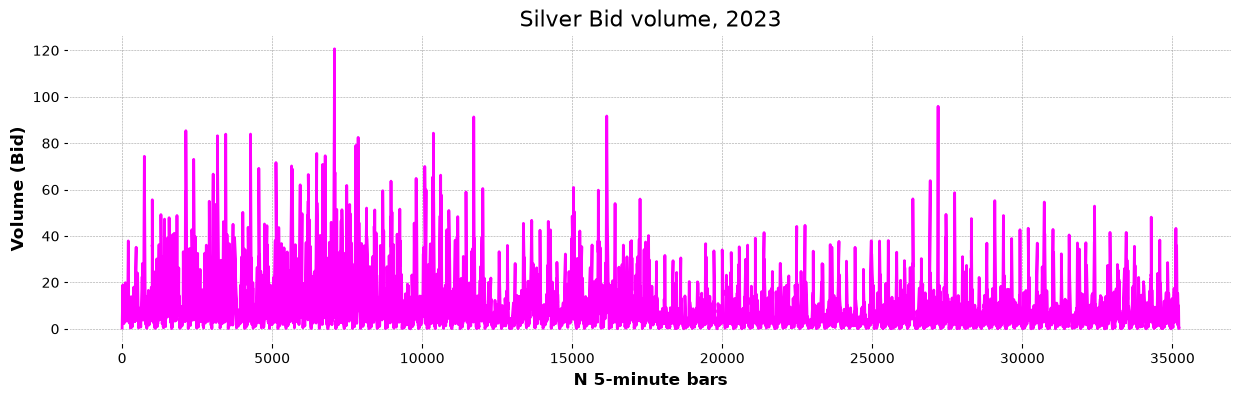

In [31]:
plt.figure(figsize=(15,4))
plt.plot(data['bid_v'], color='magenta')
plt.title('Silver Bid volume, 2023', size=16)
plt.xlabel('N 5-minute bars')
plt.ylabel('Volume (Bid)')
plt.show()

In [32]:
data['ts_prev'] = data['ts'].shift(1)

In [33]:
data['ts_gap'] = data['ts'] - data['ts_prev']

In [34]:
data.loc[data.index[0], 'ts_gap'] = "2 days 01:05:00"   # CHANGE: 2 days 01:(bar minutes). The first row starts a day and a week
data['ts_gap'].iloc[0]

Timedelta('2 days 01:05:00')

In [35]:
data[['ts_gap']][data['ts_gap'] > '0 days 00:05:00'].value_counts(sort=False)   # CHANGE: the bar size

ts_gap         
2 days 01:05:00    24
0 days 01:05:00    99
0 days 05:05:00     1
2 days 00:05:00     1
3 days 01:05:00     1
0 days 03:35:00     2
Name: count, dtype: int64

In [36]:
data['day_start'] = 0
data['week_start'] = 0

In [37]:
data.loc[data['ts_gap'] > '0 days 00:05:00', 'day_start'] = 1  

In [38]:
data.loc[data['ts_gap'] > '1 days 00:00:00', 'week_start'] = 1

In [39]:
print(data['day_start'].sum(), data['week_start'].sum())      

128 26


In [40]:
data2 = data.drop(['ts', 'ts_prev', 'ts_gap'], axis=1)

In [41]:
data2['target_hi'] = data2['bid_h']
data2['target_lo'] = data2['bid_l'] + data2['gap_l']

In [42]:
n_rows = len(data)
n_rows

35220

In [43]:
n_train = int(round(n_rows * 0.8, -3))  
n_train

28000

In [44]:
train = data.iloc[:n_train]
train.shape

(28000, 17)

In [45]:
p_hi = (train['bid_h'] + train['gap_h']).max()
p_lo = train['bid_l'].min()
print(p_hi, p_lo)

26.153 19.888


In [46]:
v_hi = max(max(train['bid_v']), max(train['ask_v']))
v_hi

365.6322

In [47]:
g_hi = round(max(max(train['gap_o']), max(train['gap_h']), max(train['gap_l']), max(train['gap_c'])), 3)
g_lo = round(min(min(train['gap_o']), min(train['gap_h']), min(train['gap_l']), min(train['gap_c'])), 3)
print(g_hi, g_lo)

0.309 0.001


In [48]:
vg_hi = train['vol_gap'].max()
vg_lo = train['vol_gap'].min()
vga_hi = train['vol_gap_abs'].max()
vga_lo = train['vol_gap_abs'].min()
print(vg_hi, vg_lo, vga_hi, vga_lo)

317.5858 -48.7912 317.5858 0.0


In [49]:
data2['bid_o'] = (data2['bid_o'] - p_lo) / (p_hi - p_lo)
data2['bid_h'] = (data2['bid_h'] - p_lo) / (p_hi - p_lo)
data2['bid_l'] = (data2['bid_l'] - p_lo) / (p_hi - p_lo)
data2['bid_c'] = (data2['bid_c'] - p_lo) / (p_hi - p_lo)
data2['target_hi'] = (data2['target_hi'] - p_lo) / (p_hi - p_lo)
data2['target_lo'] = (data2['target_lo'] - p_lo) / (p_hi - p_lo)

In [50]:
data2['ask_v'] = data2['ask_v'] / v_hi
data2['bid_v'] = data2['bid_v'] / v_hi

In [51]:
data2['vol_gap'] = (data2['vol_gap'] - vg_lo) / (vg_hi - vg_lo)

In [52]:
data2['vol_gap_abs'] = data2['vol_gap_abs'] / vga_hi

In [53]:
data2['gap_o'] = (g_hi - data2['gap_o']) / (g_hi - g_lo)
data2['gap_h'] = (g_hi - data2['gap_h']) / (g_hi - g_lo)
data2['gap_l'] = (g_hi - data2['gap_l']) / (g_hi - g_lo)
data2['gap_c'] = (g_hi - data2['gap_c']) / (g_hi - g_lo)

In [54]:
data2.head()

,bid_o,bid_h,bid_l,bid_c,bid_v,ask_v,vol_gap,vol_gap_abs,gap_o,gap_h,gap_l,gap_c,day_start,week_start,target_hi,target_lo
0,0.662091,0.665762,0.659058,0.665762,0.000952,0.000960,0.133180,0.000009,0.788961,0.788961,0.788961,0.788961,1,1,0.665762,0.669593
1,0.666560,0.677095,0.666560,0.671030,0.005048,0.003159,0.131287,0.002175,0.905844,0.814935,0.905844,0.844156,0,0,0.677095,0.671349
2,0.671349,0.671987,0.651875,0.652674,0.002470,0.002412,0.133115,0.000066,0.844156,0.840909,0.840909,0.840909,0,0,0.671987,0.659856
3,0.652674,0.653152,0.646449,0.653152,0.002445,0.002445,0.133172,0.000000,0.844156,0.847403,0.847403,0.847403,0,0,0.653152,0.654110
4,0.652833,0.660176,0.652514,0.660016,0.002429,0.002474,0.133217,0.000052,0.847403,0.844156,0.850649,0.840909,0,0,0.660176,0.660016


In [55]:
# normalisation check
pd.set_option('display.max_columns', None)
cols = ['bid_o', 'bid_h', 'bid_l', 'bid_c', 'bid_v', 'ask_v',
        'vol_gap', 'vol_gap_abs', 'gap_o', 'gap_h', 'gap_l', 'gap_c']
print(data2.iloc[:n_train][cols].describe().loc[['min', 'max']].round(3))  
print(data2.iloc[n_train:][cols].describe().loc[['min', 'max']].round(3))   

back = data2['bid_c'] * (p_hi - p_lo) + p_lo
print((back - data['bid_c']).abs().max())                                 

     bid_o  bid_h  bid_l  bid_c  bid_v  ask_v  vol_gap  vol_gap_abs  gap_o  \
min  0.001  0.004  0.000  0.001   0.00    0.0      0.0          0.0  0.403   
max  0.994  0.995  0.991  0.994   0.33    1.0      1.0          1.0  0.955   

     gap_h  gap_l  gap_c  
min  0.282  0.107 -0.000  
max  0.945  1.000  0.951  
     bid_o  bid_h  bid_l  bid_c  bid_v  ask_v  vol_gap  vol_gap_abs  gap_o  \
min  0.354  0.356  0.353  0.355  0.000  0.000    0.122        0.000  0.659   
max  0.736  0.739  0.730  0.735  0.151  0.698    0.752        0.714  0.968   

     gap_h  gap_l  gap_c  
min  0.640 -0.325  0.123  
max  0.938  0.971  0.964  
0.0


In [56]:
cols_float = ['bid_o', 'bid_h', 'bid_l', 'bid_c',
                 'bid_v', 'ask_v', 'vol_gap', 'vol_gap_abs',
                 'gap_o', 'gap_h', 'gap_l', 'gap_c',
                 'target_hi', 'target_lo']

cols_int = ['day_start', 'week_start']

In [57]:
for column in cols_float:
    data2[column] = pd.to_numeric(data2[column], downcast='float')

for column in cols_int:
    data2[column] = pd.to_numeric(data2[column], downcast='integer')

data2.info()

<class 'pandas.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   bid_o        35220 non-null  float32
 1   bid_h        35220 non-null  float32
 2   bid_l        35220 non-null  float32
 3   bid_c        35220 non-null  float32
 4   bid_v        35220 non-null  float32
 5   ask_v        35220 non-null  float32
 6   vol_gap      35220 non-null  float32
 7   vol_gap_abs  35220 non-null  float32
 8   gap_o        35220 non-null  float32
 9   gap_h        35220 non-null  float32
 10  gap_l        35220 non-null  float32
 11  gap_c        35220 non-null  float32
 12  day_start    35220 non-null  int8   
 13  week_start   35220 non-null  int8   
 14  target_hi    35220 non-null  float32
 15  target_lo    35220 non-null  float32
dtypes: float32(14), int8(2)
memory usage: 1.9 MB


In [58]:
file_obj1 = open('silver_5min_normalised.csv', 'w')
data2.to_csv('silver_5min_normalised.csv', encoding='utf-8', index=False)
file_obj1.close()

In [59]:
data = pd.read_csv('silver_5min_normalised.csv', low_memory=False, sep=',')
data.head()

,bid_o,bid_h,bid_l,bid_c,bid_v,ask_v,vol_gap,vol_gap_abs,gap_o,gap_h,gap_l,gap_c,day_start,week_start,target_hi,target_lo
0,0.662091,0.665762,0.659058,0.665762,0.000952,0.000960,0.133180,0.000009,0.788961,0.788961,0.788961,0.788961,1,1,0.665762,0.669593
1,0.666560,0.677095,0.666560,0.671029,0.005048,0.003159,0.131287,0.002175,0.905844,0.814935,0.905844,0.844156,0,0,0.677095,0.671349
2,0.671349,0.671987,0.651876,0.652674,0.002470,0.002412,0.133115,0.000066,0.844156,0.840909,0.840909,0.840909,0,0,0.671987,0.659856
3,0.652674,0.653152,0.646449,0.653152,0.002445,0.002445,0.133172,0.000000,0.844156,0.847403,0.847403,0.847403,0,0,0.653152,0.654110
4,0.652833,0.660176,0.652514,0.660016,0.002429,0.002474,0.133217,0.000052,0.847403,0.844156,0.850649,0.840909,0,0,0.660176,0.660016


In [60]:
for column in cols_float:
    data[column] = pd.to_numeric(data[column], downcast='float')

for column in cols_int:
    data[column] = pd.to_numeric(data[column], downcast='integer')

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   bid_o        35220 non-null  float32
 1   bid_h        35220 non-null  float32
 2   bid_l        35220 non-null  float32
 3   bid_c        35220 non-null  float32
 4   bid_v        35220 non-null  float32
 5   ask_v        35220 non-null  float32
 6   vol_gap      35220 non-null  float32
 7   vol_gap_abs  35220 non-null  float32
 8   gap_o        35220 non-null  float32
 9   gap_h        35220 non-null  float32
 10  gap_l        35220 non-null  float32
 11  gap_c        35220 non-null  float32
 12  day_start    35220 non-null  int8   
 13  week_start   35220 non-null  int8   
 14  target_hi    35220 non-null  float32
 15  target_lo    35220 non-null  float32
dtypes: float32(14), int8(2)
memory usage: 1.9 MB


In [61]:
feat_df = data.drop(['target_hi', 'target_lo'], axis=1)

In [62]:
ans_df = data[['target_hi', 'target_lo']]

In [63]:
ans_df = ans_df.shift(-1)

In [64]:

indexer = pd.api.indexers.FixedForwardWindowIndexer(window_size=5)   

ans_df['target_hi_next'] = ans_df['target_hi'].rolling(window=indexer).max()
ans_df['target_lo_next'] = ans_df['target_lo'].rolling(window=indexer).min()

In [65]:
ans_df = ans_df.drop(['target_hi', 'target_lo'], axis=1)

In [66]:
for i in range(5):  
    ans_df.drop(ans_df.shape[0] - 1, axis=0, inplace=True)

In [67]:
for i in range(5):  
    feat_df.drop(feat_df.shape[0] - 1, axis=0, inplace=True)

In [68]:
feat_np = np.array(feat_df)

with np.printoptions(precision=4):
    print("feat_np:")
    print(feat_np[:2, :])
    print('\n')
    print(feat_np[-2:, :])

print("numpy size: = ", feat_np.shape)
print("type: ", feat_np.dtype)

feat_np:
[[6.6209e-01 6.6576e-01 6.5906e-01 6.6576e-01 9.5178e-04 9.5998e-04
  1.3318e-01 9.4463e-06 7.8896e-01 7.8896e-01 7.8896e-01 7.8896e-01
  1.0000e+00 1.0000e+00]
 [6.6656e-01 6.7709e-01 6.6656e-01 6.7103e-01 5.0482e-03 3.1589e-03
  1.3129e-01 2.1752e-03 9.0584e-01 8.1494e-01 9.0584e-01 8.4416e-01
  0.0000e+00 0.0000e+00]]


[[0.4541 0.4563 0.4533 0.4555 0.0053 0.0095 0.1374 0.0049 0.9058 0.9058
  0.9058 0.9058 0.     0.    ]
 [0.4555 0.4571 0.4551 0.4571 0.001  0.004  0.1362 0.0034 0.9058 0.9058
  0.9058 0.9058 0.     0.    ]]
numpy size: =  (35215, 14)
type:  float32


In [69]:
ans_np = np.array(ans_df)

print("ans_np:")
print(ans_np[:3, :])
print('\n')
print(ans_np[-3:, :])

print("numpy size: = ", ans_np.shape)
print("type: ", ans_np.dtype)
print(np.isnan(ans_np).sum(), 'missing values in ans_np (must be 0)')

ans_np:
[[0.677095   0.65411013]
 [0.6724661  0.65411013]
 [0.6724661  0.65411013]]


[[0.45714286 0.45810056]
 [0.45857942 0.45985633]
 [0.4593775  0.46017557]]
numpy size: =  (35215, 2)
type:  float64
0 missing values in ans_np (must be 0)


In [70]:
from tqdm import tqdm

In [71]:
n_small = 30000  
N = 50  
L = n_small - N
t = feat_np.shape[1]
print('Size of a three-dimensional inputs tensor: ', L, N, t)

Size of a three-dimensional inputs tensor:  29950 50 14


In [72]:
tensor_x = np.zeros((L, N, t), dtype='float32')

In [73]:
Y = np.zeros((L, 2), dtype='float32')

In [74]:
print('L = n_small - N = ', n_small - N, L)

for k in tqdm(range(L)):
    tensor_x[k, :, :] = feat_np[k:k+N, :]

    Y[k, 0] = ans_np[k+N-1, 0]

    Y[k, 1] = ans_np[k+N-1, 1]

print(k)
print("Numpy size:        ", tensor_x.shape, '\n')

print(Y[:5, :])
print(Y[-10:, :])
print("Numpy size:         ", Y.shape)

L = n_small - N =  29950 29950


100%|██████████| 29950/29950 [00:00<00:00, 88571.53it/s]

29949
Numpy size:         (29950, 50, 14) 

[[0.72897047 0.7061452 ]
 [0.72897047 0.7061452 ]
 [0.72897047 0.71093374]
 [0.72897047 0.7093376 ]
 [0.7177973  0.7088587 ]]
[[0.5905826  0.5896249 ]
 [0.590423   0.5896249 ]
 [0.58946526 0.5896249 ]
 [0.58930564 0.5896249 ]
 [0.588348   0.5896249 ]
 [0.588348   0.5897845 ]
 [0.58754987 0.5897845 ]
 [0.58754987 0.5897845 ]
 [0.58754987 0.5899441 ]
 [0.58754987 0.5899441 ]]
Numpy size:          (29950, 2)


In [75]:
import random

pp = random.randint(50, L - 20)    
print('random int = ', pp)

print('tensor_x:', '\t\t', 'Y:')
print('bid_h', '\t\t', 'target_hi')

for i in range(15):
    print(tensor_x[pp+i, N-1, 1], '\t\t', Y[pp+i, 0])

random int =  12082
tensor_x: 		 Y:
bid_h 		 target_hi
0.21548285 		 0.21372706
0.21372706 		 0.21292897
0.20893855 		 0.21292897
0.20877893 		 0.21356744
0.20973663 		 0.21723862
0.21245012 		 0.21931365
0.21292897 		 0.22059058
0.21149242 		 0.22250599
0.21356744 		 0.22250599
0.21723862 		 0.22330406
0.21931365 		 0.22330406
0.22059058 		 0.22330406
0.22250599 		 0.2236233
0.22090982 		 0.22490025
0.22330406 		 0.22490025


In [76]:
filled = (np.abs(tensor_x).sum(axis=(1, 2)) > 0).sum()
print(filled, L)                    

29950 29950


In [77]:
data = []
feat_df = []
ans_df = []
feat_np = []
ans_np = []

In [78]:
from sklearn.model_selection import train_test_split

In [79]:
X_train, X_test, y_train, y_test = train_test_split(tensor_x, Y, test_size=0.1,   
                                                    shuffle=False, stratify=None, random_state=101)

In [80]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)
print(np.isnan(X_train).sum(), np.isnan(y_train).sum(), np.isnan(X_test).sum(), np.isnan(y_test).sum())

(26955, 50, 14)
(26955, 2)
(2995, 50, 14)
(2995, 2)
0 0 0 0


In [81]:
model = keras.Sequential([

    keras.layers.Conv1D(50, 9, padding='same', input_shape=(N, t), activation=tf.nn.relu, kernel_initializer="normal"),
    keras.layers.MaxPooling1D(7),
    keras.layers.Conv1D(100, 7, padding='same', activation=tf.nn.relu, kernel_initializer="normal"),
    keras.layers.GlobalMaxPooling1D(),
    keras.layers.Dense(25, activation=tf.nn.relu, kernel_initializer="normal"),

    keras.layers.Dense(2)
])

C:\Users\Arshpreet Singh\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [82]:
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 50, 50)         │         6,350 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 7, 50)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 7, 100)         │        35,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 100)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         2,525 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            52 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,027 (171.98 KB)

 Trainable params: 44,027 (171.98 KB)

 Non-trainable params: 0 (0.00 B)

None


In [83]:
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

In [84]:
history = model.fit(X_train, y_train, batch_size=30, epochs=15, validation_split=0.2, verbose=1)

Epoch 1/15
719/719 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - loss: 0.0052 - mae: 0.0243 - val_loss: 5.6466e-04 - val_mae: 0.0189
Epoch 2/15
719/719 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 1.9924e-04 - mae: 0.0103 - val_loss: 2.0574e-04 - val_mae: 0.0100
Epoch 3/15
719/719 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 1.3987e-04 - mae: 0.0086 - val_loss: 2.3361e-04 - val_mae: 0.0123
Epoch 4/15
719/719 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 1.1678e-04 - mae: 0.0079 - val_loss: 1.9434e-04 - val_mae: 0.0110
Epoch 5/15
719/719 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 1.0659e-04 - mae: 0.0075 - val_loss: 1.0798e-04 - val_mae: 0.0069
Epoch 6/15
719/719 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 9.9733e-05 - mae: 0.0072 - val_loss: 1.0426e-04 - val_mae: 0.0070
Epoch 7/15
719/719 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - loss: 9.3704e-05 - mae: 0.0070 - val_loss: 1.0806e-04 - val_mae: 0.0072
Epoch 8/15
719/719 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - loss: 8.8820e-05 - mae: 0.0068 - val_loss: 1.1939e-04 - val_

findfont: Failed to find font weight semibold, now using 700.


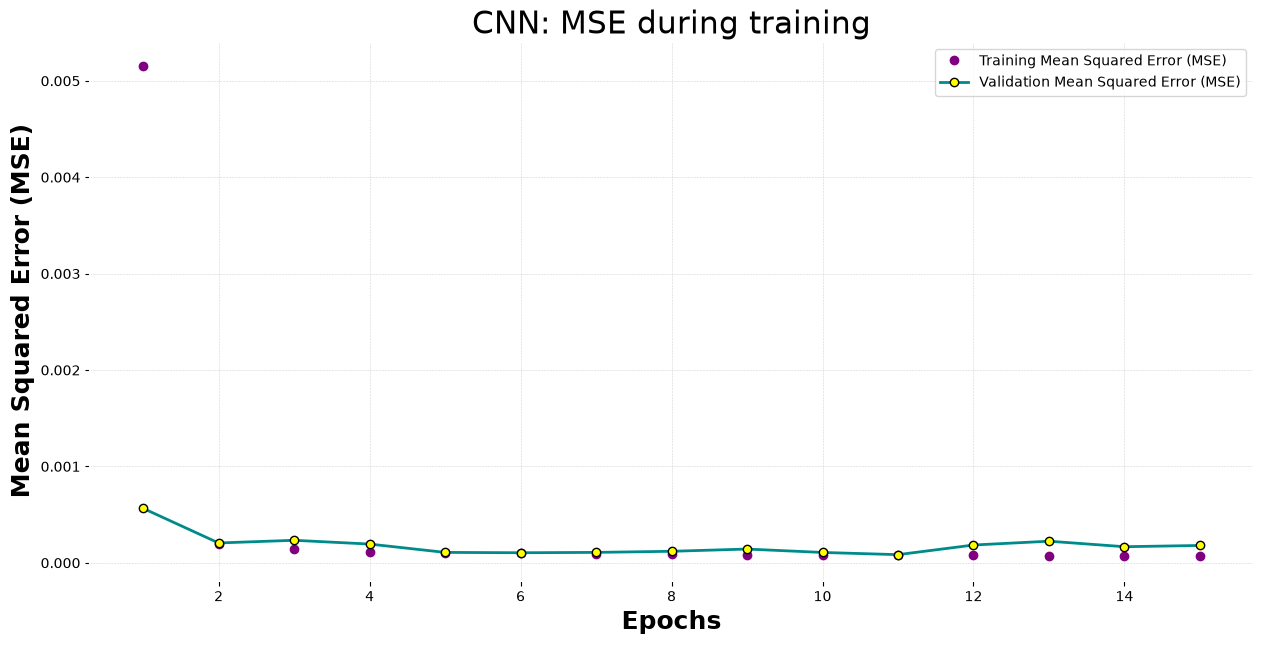

In [85]:
history_dict = history.history

mse_values = history_dict['loss']
val_mse_values = history_dict['val_loss']

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'o', color='purple', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, color='darkcyan', linewidth=2, marker='o', markeredgecolor='black', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.title('CNN: MSE during training', size=22)
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.grid(True, color='lightgray', linestyle='--')
plt.legend()
plt.show()

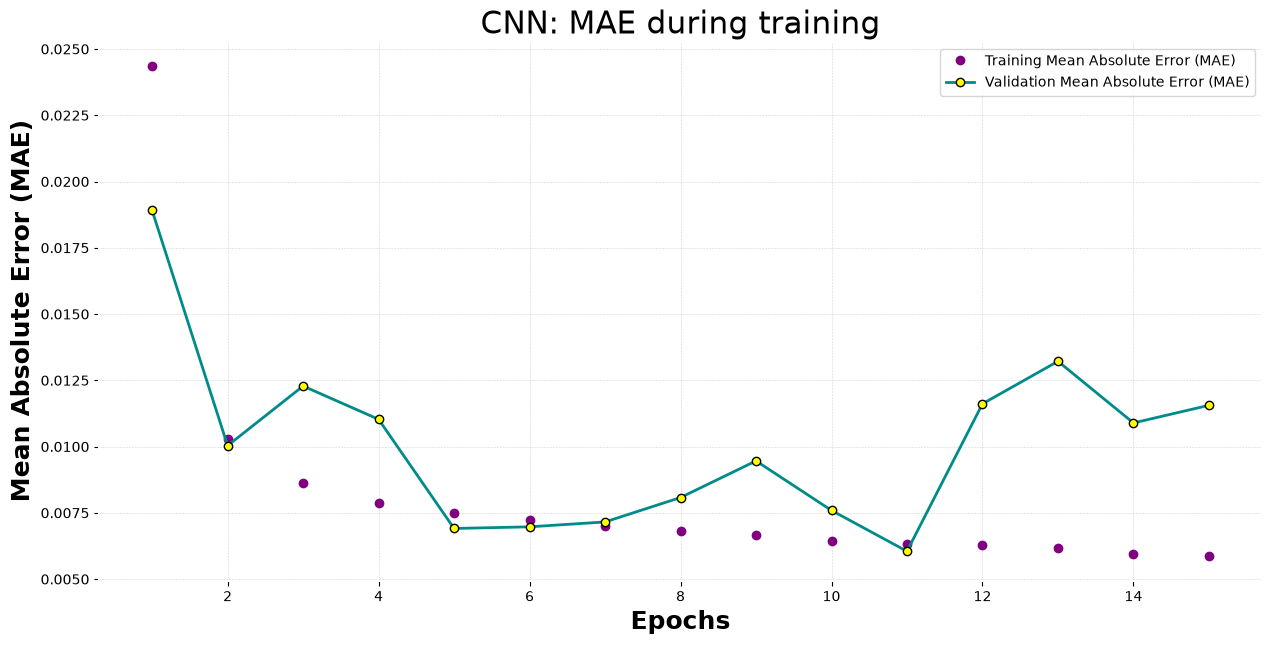

In [86]:
mean_absolute_error_values = history_dict['mae']
val_mean_absolute_error_values = history_dict['val_mae']

epochs = range(1, len(mean_absolute_error_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mean_absolute_error_values, 'o', color='purple', label='Training Mean Absolute Error (MAE)')
plt.plot(epochs, val_mean_absolute_error_values, color='darkcyan', linewidth=2, marker='o', markeredgecolor='black', markerfacecolor='yellow', label='Validation Mean Absolute Error (MAE)')
plt.title('CNN: MAE during training', size=22)
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Absolute Error (MAE)', size=18)
plt.grid(True, color='lightgray', linestyle='--')
plt.legend()
plt.show()

In [87]:
mse, mae = model.evaluate(X_test, y_test, verbose=1)

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.3532e-04 - mae: 0.0103


In [88]:
print("Mean absolute error: %.5f" % mae)
print("Mean squared error: %.5f" % mse)
print("Mean absolute error in dollars: %.4f" % (mae * (p_hi - p_lo)))

Mean absolute error: 0.01033
Mean squared error: 0.00014
Mean absolute error in dollars: 0.0647


In [89]:
pred = model.predict(X_test)
print(pred)

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
[[0.6276533  0.6278936 ]
 [0.6192957  0.6189232 ]
 [0.63129574 0.63171244]
 ...
 [0.58039683 0.5788512 ]
 [0.5798036  0.57839197]
 [0.5797859  0.57847494]]


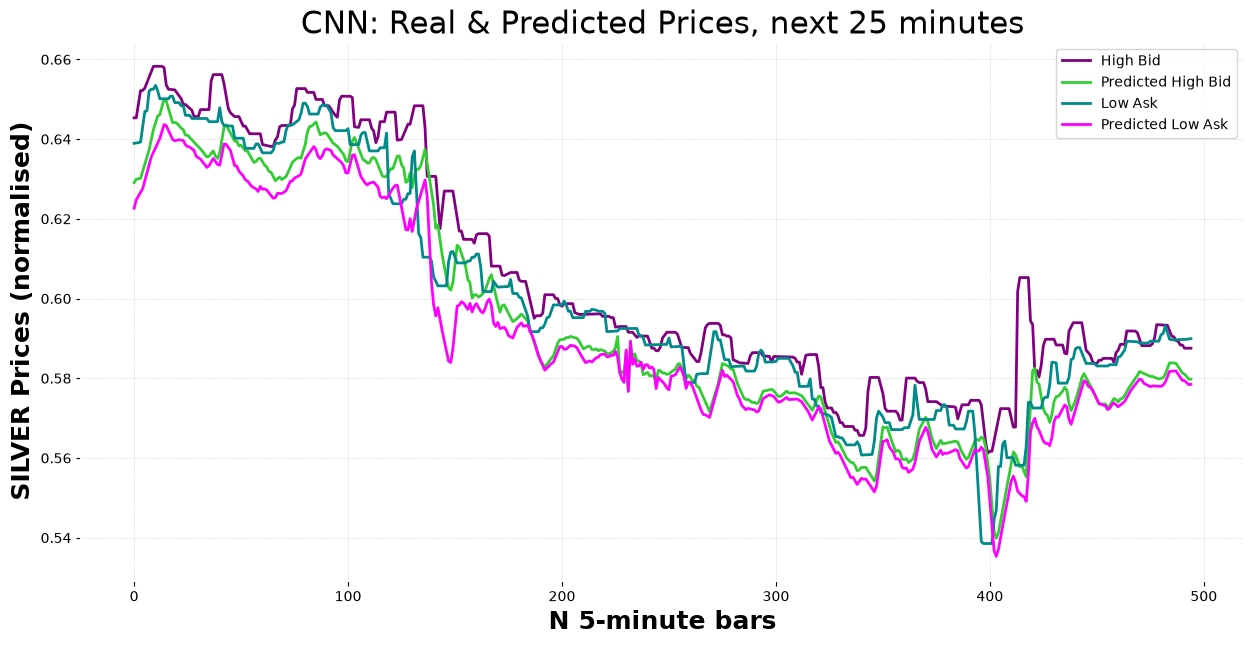

In [90]:
N1 = 2500
LL = 500
N2 = N1 + LL

fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)
line1, = ax1.plot(y_test[N1:N2, 0], label='High Bid', color='purple')
line2, = ax1.plot(pred[N1:N2, 0], label='Predicted High Bid', color='limegreen')
line3, = ax1.plot(y_test[N1:N2, 1], label='Low Ask', color='darkcyan')
line4, = ax1.plot(pred[N1:N2, 1], label='Predicted Low Ask', color='magenta')

plt.title('CNN: Real & Predicted Prices, next 25 minutes', size=22)
plt.ylabel('SILVER Prices (normalised)', size=18)
plt.xlabel('N 5-minute bars', size=18)
plt.grid(True, color='lightgray', linestyle='--')
plt.legend(loc='upper right')

plt.show()

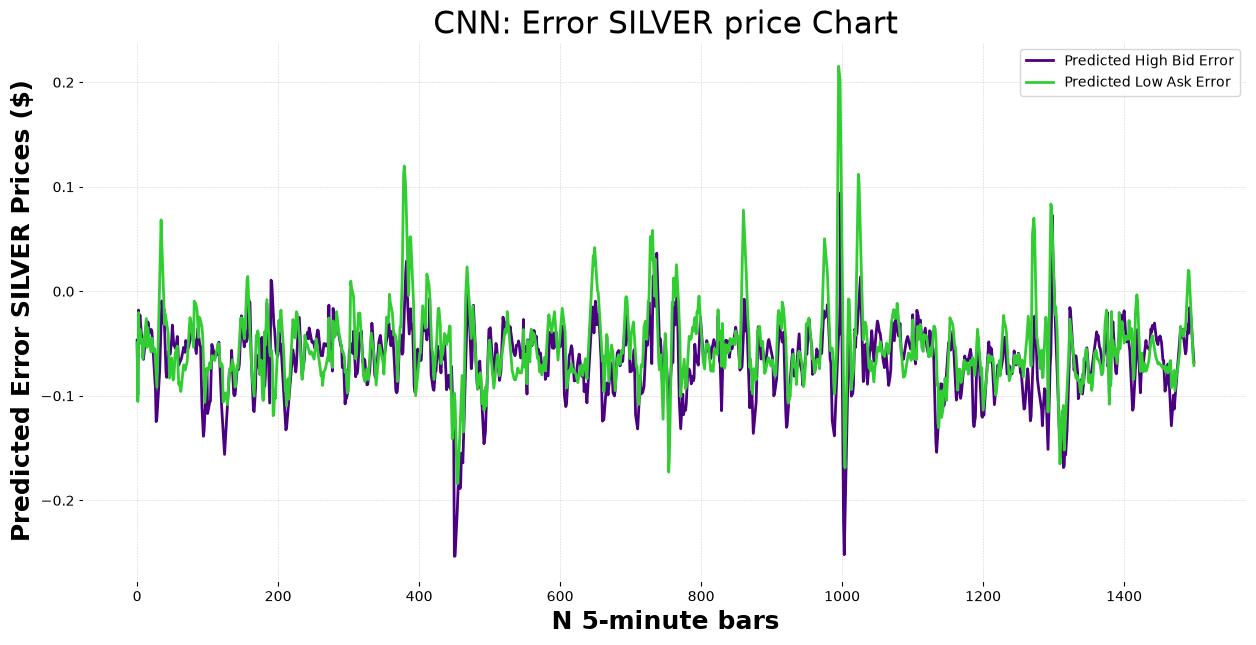

In [91]:
N1 = 0
LL = 1500
N2 = N1 + LL

fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)

a = (pred[N1:N2, 0] - y_test[N1:N2, 0]) * (p_hi - p_lo)
b = (pred[N1:N2, 1] - y_test[N1:N2, 1]) * (p_hi - p_lo)

line1, = ax1.plot(a, label='Predicted High Bid Error', color='indigo')
line2, = ax1.plot(b, label='Predicted Low Ask Error', color='limegreen')

plt.title('CNN: Error SILVER price Chart', size=22)
plt.ylabel('Predicted Error SILVER Prices ($)', size=18)
plt.xlabel('N 5-minute bars', size=18)
plt.grid(True, color='lightgray', linestyle='--')
plt.legend(loc='upper right')

plt.show()

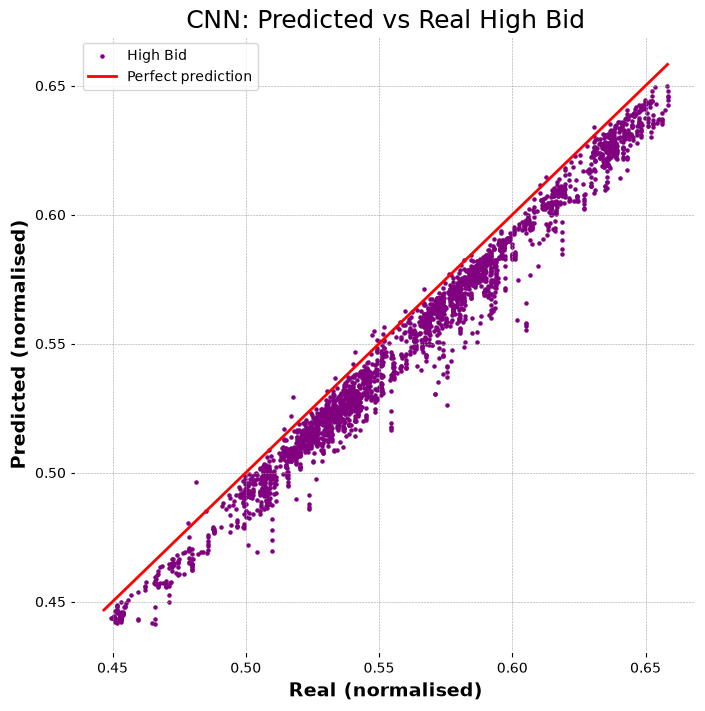

In [92]:
plt.figure(figsize=(8,8))
plt.scatter(y_test[:, 0], pred[:, 0], s=5, color='purple', label='High Bid')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', label='Perfect prediction')
plt.title('CNN: Predicted vs Real High Bid', size=18)
plt.xlabel('Real (normalised)', size=14)
plt.ylabel('Predicted (normalised)', size=14)
plt.legend()
plt.show()

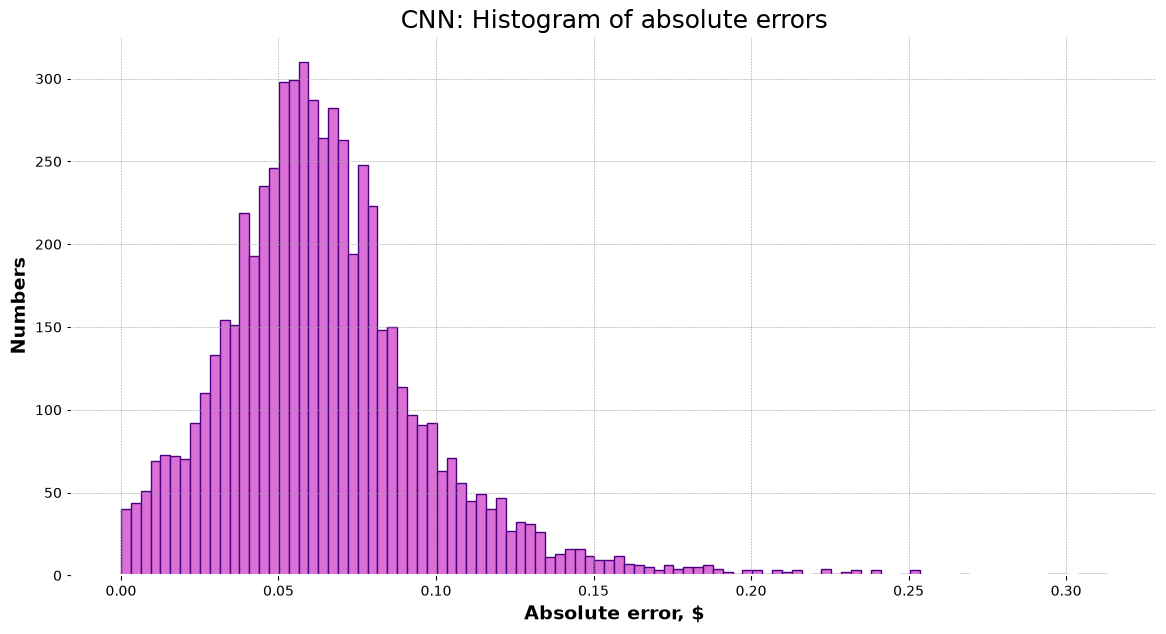

In [93]:
abs_error = np.abs(pred - y_test) * (p_hi - p_lo)
plt.figure(figsize=(14,7))
plt.hist(abs_error.flatten(), bins=100, color='orchid', edgecolor='indigo')
plt.title('CNN: Histogram of absolute errors', size=18)
plt.xlabel('Absolute error, $', size=14)
plt.ylabel('Numbers', size=14)
plt.show()

In [94]:
pred_dollars = pred * (p_hi - p_lo) + p_lo
real_dollars = y_test * (p_hi - p_lo) + p_lo

result = pd.DataFrame({'Predicted max High Bid ($)': pred_dollars[:, 0],
                       'Real max High Bid ($)': real_dollars[:, 0],
                       'Predicted min Low Ask ($)': pred_dollars[:, 1],
                       'Real min Low Ask ($)': real_dollars[:, 1]})
result.tail(5).round(3)

,Predicted max High Bid ($),Real max High Bid ($),Predicted min Low Ask ($),Real min Low Ask ($)
2990,23.530,23.574,23.518,23.583
2991,23.528,23.569,23.518,23.583
2992,23.524,23.569,23.515,23.583
2993,23.520,23.569,23.512,23.584
2994,23.520,23.569,23.512,23.584
